In [20]:
# Imports and Config
import os
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Plot styling
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

In [21]:
# Load the Data
data_path = os.path.join("..", "data", "raw", "heart_disease.csv")
df = pd.read_csv(data_path)

print("First 5 records:")
display(df.head())
print("\nDataset Info:")
df.info()

First 5 records:


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
0,63,1,1,145,233,1,2,150,0,2.3,3,0.0,6.0,0
1,67,1,4,160,286,0,2,108,1,1.5,2,3.0,3.0,2
2,67,1,4,120,229,0,2,129,1,2.6,2,2.0,7.0,1
3,37,1,3,130,250,0,0,187,0,3.5,3,0.0,3.0,0
4,41,0,2,130,204,0,2,172,0,1.4,1,0.0,3.0,0



Dataset Info:
<class 'pandas.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    int64  
 1   sex       303 non-null    int64  
 2   cp        303 non-null    int64  
 3   trestbps  303 non-null    int64  
 4   chol      303 non-null    int64  
 5   fbs       303 non-null    int64  
 6   restecg   303 non-null    int64  
 7   thalach   303 non-null    int64  
 8   exang     303 non-null    int64  
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    int64  
 11  ca        299 non-null    float64
 12  thal      301 non-null    float64
 13  num       303 non-null    int64  
dtypes: float64(3), int64(11)
memory usage: 33.3 KB


In [22]:
# Missing Value Assessment
missing = df.isnull().sum()
missing_percent = (missing / len(df)) * 100
missing_df = pd.DataFrame({"Missing Count": missing, "Percentage (%)": missing_percent})
print(missing_df[missing_df["Missing Count"] > 0])

      Missing Count  Percentage (%)
ca                4        1.320132
thal              2        0.660066


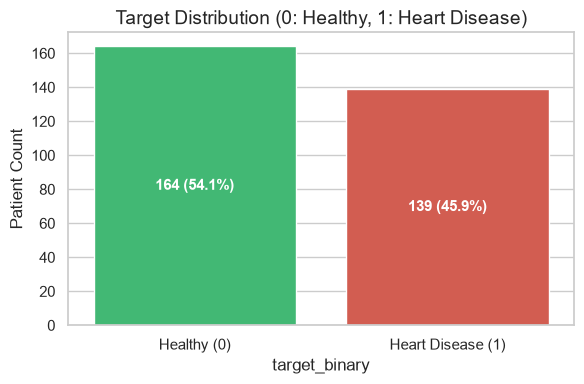

target_binary
0    0.541254
1    0.458746
Name: proportion, dtype: float64


In [23]:
# Target Variable Analysis (Class Balance)
# UCI dataset 'num' column has values 0 (no disease) to 1, 2, 3, 4 (different severities).
# For binary classification: 0 -> 0 (No Heart Disease), >0 -> 1 (Heart Disease).
df["target_binary"] = (df["num"] > 0).astype(int)

fig, ax = plt.subplots(figsize=(6, 4))
sns.countplot(
    data=df,
    x="target_binary",
    hue="target_binary",
    palette=["#2ecc71", "#e74c3c"],
    legend=False,
    ax=ax,
)

ax.set_title("Target Distribution (0: Healthy, 1: Heart Disease)", fontsize=14)
ax.set_xticks([0, 1])
ax.set_xticklabels(["Healthy (0)", "Heart Disease (1)"])
ax.set_ylabel("Patient Count")

for p in ax.patches:
  height = p.get_height()
  if height > 0:
    ax.annotate(
        f"{int(height)} ({height/len(df):.1%})",
        (p.get_x() + p.get_width() / 2.0, height / 2.0),
        ha="center",
        va="center",
        color="white",
        fontweight="bold",
        fontsize=11,
    )

plt.tight_layout()
os.makedirs("../data/processed", exist_ok=True)
plt.savefig("../data/processed/class_balance.png", dpi=150)
plt.show()

# Print class counts
print(df["target_binary"].value_counts(normalize=True))

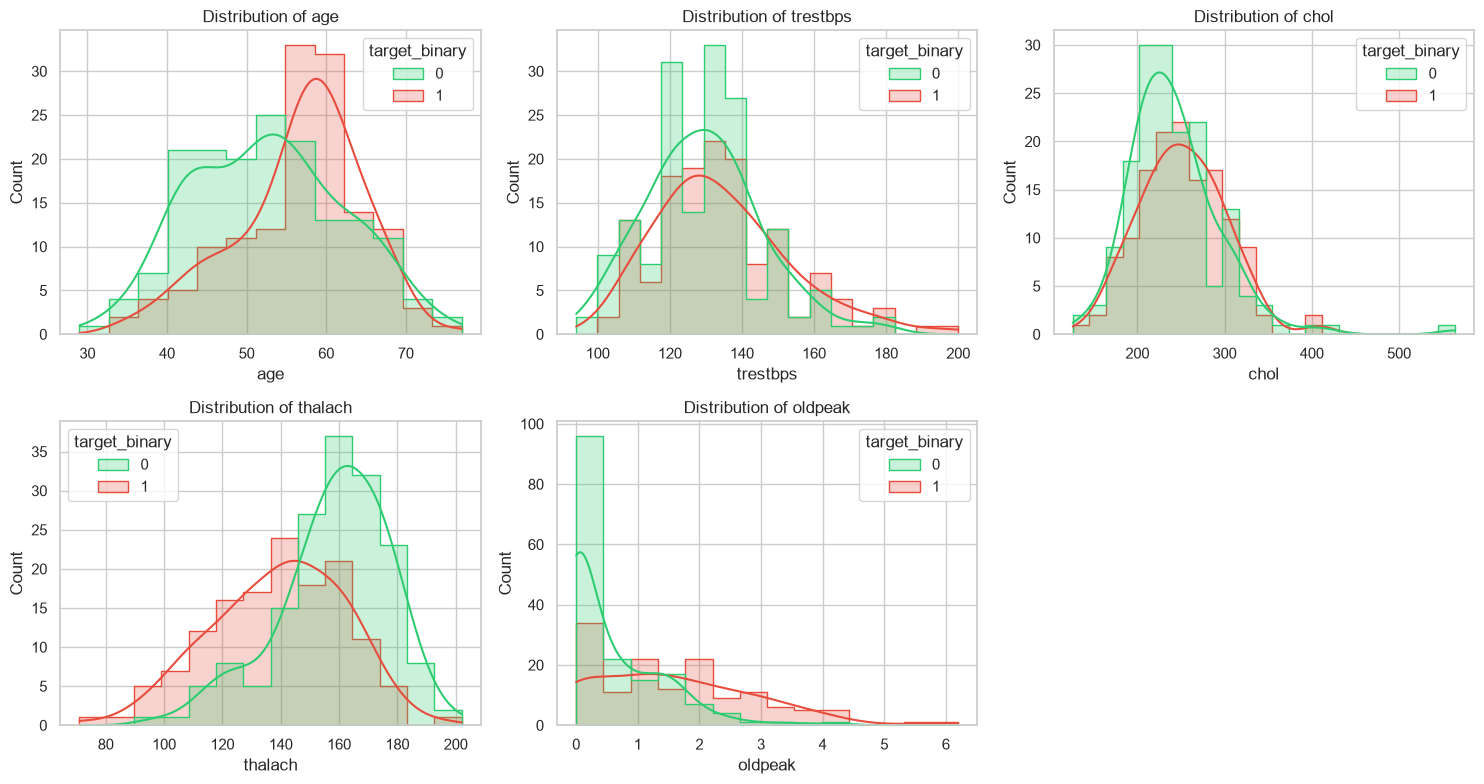

In [24]:
# Numerical Feature Distributions (Histograms)
num_cols = ["age", "trestbps", "chol", "thalach", "oldpeak"]

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()

for i, col in enumerate(num_cols):
  sns.histplot(
      data=df,
      x=col,
      hue="target_binary",
      kde=True,
      element="step",
      palette=["#2ecc71", "#e74c3c"],
      ax=axes[i],
  )
  axes[i].set_title(f"Distribution of {col}", fontsize=12)

# Remove unused 6th subplot
fig.delaxes(axes[5])
plt.tight_layout()
plt.savefig("../data/processed/numerical_distributions.png", dpi=150)
plt.show()

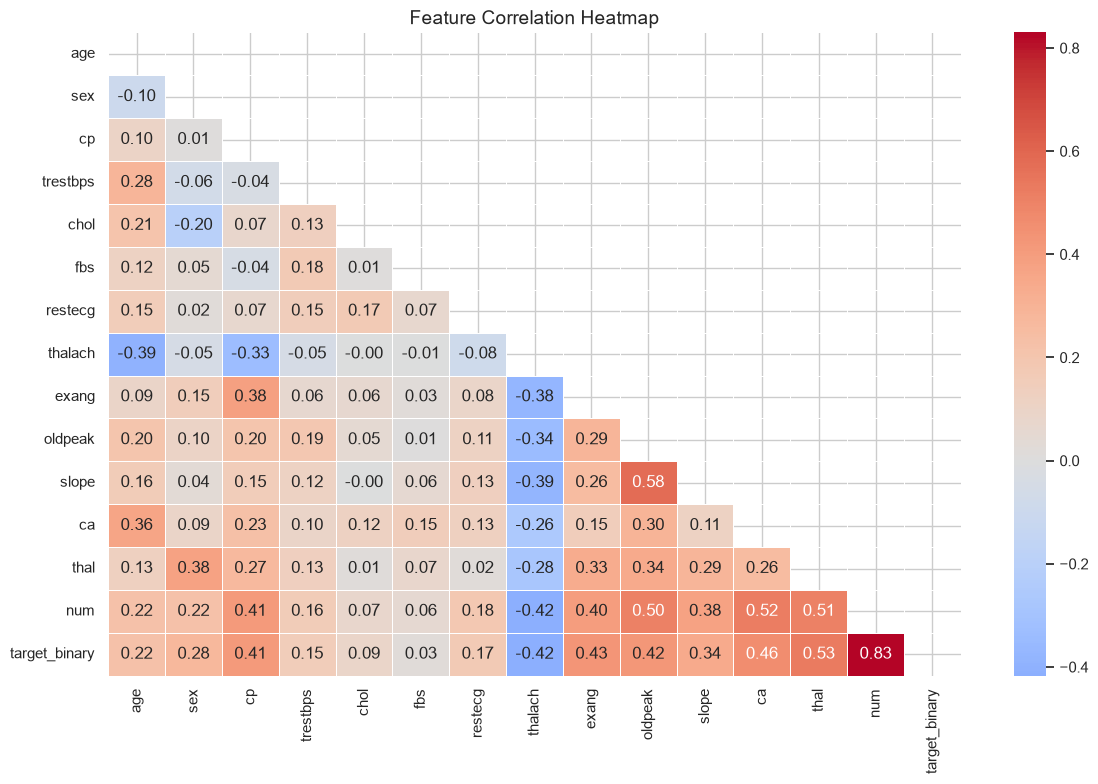

In [25]:
# Correlation Heatmap
plt.figure(figsize=(12, 8))
corr_matrix = df.corr()
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(
    corr_matrix,
    mask=mask,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    linewidths=0.5,
)
plt.title("Feature Correlation Heatmap", fontsize=14)
plt.tight_layout()
plt.savefig("../data/processed/correlation_heatmap.png", dpi=150)
plt.show()